# U1 - Integrante 3 - Clasificacion del rol del comprador (`is_buyer_maker`)

**Proyecto Sello · BTC/USDT (Binance) · `BTCUSDT-trades-2026-01-05.csv`**

**Pregunta de negocio:** ¿es posible predecir si el comprador fue maker a partir del precio, la cantidad y el monto operado?

## Mejoras respecto a la version entregada
1. **Modelo ganador seleccionado por codigo** (no a mano) y guardado como **`PipelineModel` completo** (VectorAssembler + escalado + modelo), de modo que la Unidad 2 pueda aplicarlo directamente sobre el stream.
2. **Division cronologica 80/20** (entrenar con el pasado, probar con el futuro) en lugar de `randomSplit`, sin fuga de informacion.
3. **Baseline explicito** y mas de una configuracion por algoritmo; todas las metricas se calculan y se reportan desde el codigo (sin cifras escritas a mano en los graficos).
4. **Silver con esquema unico** (`event_ts_ms` en milisegundos como el WebSocket, `trade_type`, `es_ballena`) y **Gold doble**: Gold ML particionado y Gold KPI por minuto.
5. **Controles de calidad** documentados y **prueba de contrato de inferencia** con un evento real del WebSocket.
6. Metricas, rutas y features exportadas a `metricas_integrante3.json`.

> Ejecutar de arriba hacia abajo. Rutas por defecto: datos en `/opt/data`, artefactos en `/opt/artifacts` (se cambian con `DATA_PATH` y `ARTIFACTS_DIR`). Para una prueba rapida: `SAMPLE_FRACTION=0.05`.

## 1. Spark Session y parametros

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, LongType, DoubleType, BooleanType, StringType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.functions import vector_to_array

# --- Parametros (se pueden sobreescribir con variables de entorno) ---
INTEGRANTE    = 3
DATA_PATH     = os.getenv("DATA_PATH", "/home/jovyan/work/data/BTCUSDT-trades-2026-01-05.csv")
ARTIFACTS     = os.getenv("ARTIFACTS_DIR", "/home/jovyan/work/artifacts")
SAMPLE_FRAC   = float(os.getenv("SAMPLE_FRACTION", "1.0"))   # < 1.0 solo para pruebas rapidas
UMBRAL_BALLENA = 50000.0                                      # USDT
SEED          = 42

spark = (
    SparkSession.builder
    .appName("U1-Integrante3-ClasificacionRol")
    .master("local[*]")
    .config("spark.ui.port", "4040")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.session.timeZone", "UTC")   # trade_date consistente
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
spark

## 2. Bronze: carga con esquema explicito

In [2]:
schema = StructType([
    StructField("trade_id",       LongType(),    False),
    StructField("price",          DoubleType(),  True),
    StructField("qty",            DoubleType(),  True),
    StructField("quote_qty",      DoubleType(),  True),
    StructField("time_us",        LongType(),    False),   # microsegundos (el WebSocket usa milisegundos)
    StructField("is_buyer_maker", BooleanType(), True),
    StructField("is_best_match",  BooleanType(), True),
])

df_bronze = spark.read.csv(DATA_PATH, schema=schema, header=False)
if SAMPLE_FRAC < 1.0:
    df_bronze = df_bronze.sample(False, SAMPLE_FRAC, SEED)

df_bronze.printSchema()
df_bronze.show(5, truncate=False)

root
 |-- trade_id: long (nullable = true)
 |-- price: double (nullable = true)
 |-- qty: double (nullable = true)
 |-- quote_qty: double (nullable = true)
 |-- time_us: long (nullable = true)
 |-- is_buyer_maker: boolean (nullable = true)
 |-- is_best_match: boolean (nullable = true)

+----------+--------+-------+-----------+----------------+--------------+-------------+
|trade_id  |price   |qty    |quote_qty  |time_us         |is_buyer_maker|is_best_match|
+----------+--------+-------+-----------+----------------+--------------+-------------+
|5734054604|91529.74|2.2E-4 |20.1365428 |1767571200308618|false         |true         |
|5734054605|91529.74|0.01   |915.2974   |1767571200375801|false         |true         |
|5734054606|91529.74|0.00437|399.9849638|1767571200477157|false         |true         |
|5734054607|91529.74|0.00764|699.2872136|1767571200480543|false         |true         |
|5734054608|91529.74|0.00136|124.4804464|1767571200545508|false         |true         |
+--------

## 3. Calidad de datos sobre Bronze

In [3]:
# Controles de calidad sobre Bronze (evidencia para el criterio 3 de la rubrica)
n_bronze = df_bronze.count()
n_unicos = df_bronze.select("trade_id").distinct().count()
print(f"Registros Bronze        : {n_bronze:,}")
print(f"trade_id unicos         : {n_unicos:,}  -> duplicados: {n_bronze - n_unicos:,}")

print("\nNulos por columna:")
df_bronze.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df_bronze.columns]).show()

n_invalidos = df_bronze.filter((F.col("price") <= 0) | (F.col("qty") <= 0) | (F.col("quote_qty") <= 0)).count()
print(f"Filas con price/qty/quote_qty <= 0: {n_invalidos:,}")

# Consistencia algebraica: quote_qty = price * qty (explica las metricas casi perfectas de U1)
err = df_bronze.select(
    F.max(F.abs(F.col("quote_qty") - F.col("price") * F.col("qty")) / F.col("quote_qty")).alias("max_err_rel")
).first()["max_err_rel"]
print(f"Error relativo maximo |quote_qty - price*qty| / quote_qty = {err:.2e}")

Registros Bronze        : 5,485,489
trade_id unicos         : 5,485,489  -> duplicados: 0

Nulos por columna:
+--------+-----+---+---------+-------+--------------+-------------+
|trade_id|price|qty|quote_qty|time_us|is_buyer_maker|is_best_match|
+--------+-----+---+---------+-------+--------------+-------------+
|       0|    0|  0|        0|      0|             0|            0|
+--------+-----+---+---------+-------+--------------+-------------+

Filas con price/qty/quote_qty <= 0: 0
Error relativo maximo |quote_qty - price*qty| / quote_qty = 3.13e-16


## 4. Silver: limpieza, deduplicacion, validacion y enriquecimiento

In [4]:
# Silver: limpio, deduplicado, validado y enriquecido (esquema IDENTICO en los 4 notebooks)
#  - event_ts_ms normaliza el tiempo a MILISEGUNDOS, igual que el campo T del WebSocket.
#  - trade_type: is_buyer_maker = True significa que el comprador era el maker (el agresor/taker vendio).
df_silver = (
    df_bronze
    .na.drop(subset=["trade_id", "price", "is_buyer_maker"])
    .dropDuplicates(["trade_id"])
    .filter((F.col("price") > 0) & (F.col("qty") > 0) & (F.col("quote_qty") > 0))
    .withColumn("event_ts_ms", F.floor(F.col("time_us") / 1000).cast("long"))
    .withColumn("event_timestamp", (F.col("time_us") / 1000000).cast("timestamp"))
    .withColumn("trade_date", F.to_date("event_timestamp"))
    .withColumn("is_buyer_maker_num", F.when(F.col("is_buyer_maker") == True, 1.0).otherwise(0.0))
    .withColumn("trade_type", F.when(F.col("is_buyer_maker") == True, "BUYER_MAKER").otherwise("BUYER_TAKER"))
    .withColumn("es_ballena", F.when(F.col("quote_qty") > UMBRAL_BALLENA, 1.0).otherwise(0.0))
)

ruta_silver = f"{ARTIFACTS}/silver_integrante3"
(df_silver.repartition(1, "trade_type")
    .write.mode("overwrite").partitionBy("trade_type").parquet(ruta_silver))

df_silver = spark.read.parquet(ruta_silver)
print(f"Registros Silver: {df_silver.count():,}")
df_silver.show(5, truncate=False)

Registros Silver: 5,485,489
+----------+--------+-------+-------------+----------------+--------------+-------------+-------------+--------------------------+----------+------------------+----------+-----------+
|trade_id  |price   |qty    |quote_qty    |time_us         |is_buyer_maker|is_best_match|event_ts_ms  |event_timestamp           |trade_date|is_buyer_maker_num|es_ballena|trade_type |
+----------+--------+-------+-------------+----------------+--------------+-------------+-------------+--------------------------+----------+------------------+----------+-----------+
|5734054604|91529.74|2.2E-4 |20.1365428   |1767571200308618|false         |true         |1767571200308|2026-01-05 00:00:00.308618|2026-01-05|0.0               |0.0       |BUYER_TAKER|
|5734054610|91529.74|5.4E-4 |49.4260596   |1767571200665868|false         |true         |1767571200665|2026-01-05 00:00:00.665868|2026-01-05|0.0               |0.0       |BUYER_TAKER|
|5734054624|91529.74|0.20378|18651.9304172|176757120

## 5. Gold: tabla ML particionada por `is_best_match` + KPIs por minuto

In [5]:
# Gold (1/2) - Gold ML: tabla lista para entrenar, particionada por is_best_match (baja cardinalidad)
cols_gold = ["trade_id", "time_us", "event_ts_ms", "price", "qty", "quote_qty",
             "is_buyer_maker", "is_buyer_maker_num", "is_best_match", "es_ballena", "trade_type"]
ruta_gold = f"{ARTIFACTS}/gold_integrante3"
df_silver.select(*cols_gold).write.mode("overwrite").partitionBy("is_best_match").parquet(ruta_gold)

df_gold = spark.read.parquet(ruta_gold)
# Las columnas de particion se leen de vuelta como string/double: se restauran sus tipos
for c in ["is_buyer_maker", "is_best_match"]:
    if c in df_gold.columns:
        df_gold = df_gold.withColumn(c, F.col(c).cast("boolean"))
df_gold = df_gold.withColumn("es_ballena", F.col("es_ballena").cast("double"))
print("Particiones Gold ML:")
df_gold.groupBy("is_best_match").count().show()

# Gold (2/2) - Gold KPI: agregado de negocio por minuto (insumo para BI/Grafana en la Unidad 2)
df_kpi = (
    df_silver
    .withColumn("minuto", F.date_trunc("minute", "event_timestamp"))
    .groupBy("trade_date", "minuto")
    .agg(
        F.count("*").alias("n_trades"),
        F.sum("qty").alias("volumen_btc"),
        F.sum("quote_qty").alias("volumen_usdt"),
        (F.sum("quote_qty") / F.sum("qty")).alias("vwap"),
        F.min("price").alias("precio_min"),
        F.max("price").alias("precio_max"),
        F.sum("es_ballena").alias("n_ballenas"),
        F.avg("is_buyer_maker_num").alias("pct_buyer_maker"),
    )
    .orderBy("minuto")
)
ruta_kpi = f"{ARTIFACTS}/gold_kpi_integrante3"
df_kpi.write.mode("overwrite").partitionBy("trade_date").parquet(ruta_kpi)
print(f"Minutos agregados en Gold KPI: {spark.read.parquet(ruta_kpi).count():,}")
spark.read.parquet(ruta_kpi).orderBy("minuto").show(5, truncate=False)

Particiones Gold ML:
+-------------+-------+
|is_best_match|  count|
+-------------+-------+
|         true|5485489|
+-------------+-------+

Minutos agregados en Gold KPI: 1,440
+-------------------+--------+------------------+-------------------+-----------------+----------+----------+----------+-------------------+----------+
|minuto             |n_trades|volumen_btc       |volumen_usdt       |vwap             |precio_min|precio_max|n_ballenas|pct_buyer_maker    |trade_date|
+-------------------+--------+------------------+-------------------+-----------------+----------+----------+----------+-------------------+----------+
|2026-01-05 00:00:00|4460    |21.900430000000156|2005031.6089070006 |91552.15714517872|91514.81  |91592.43  |3.0       |0.3672645739910314 |2026-01-05|
|2026-01-05 00:01:00|25542   |561.746150000003  |5.164629774760005E7|91938.85485036216|91592.42  |92059.13  |129.0     |0.34860230209067417|2026-01-05|
|2026-01-05 00:02:00|11135   |53.629030000002885|4930045.9038

## 6. Division cronologica entrenamiento / prueba

In [6]:
# Division CRONOLOGICA 80/20 (no aleatoria): se entrena con el pasado y se prueba con el futuro.
# Evita fuga de informacion y es la misma disciplina que exige S10 (series de tiempo).
FEATURES = ['price', 'qty', 'quote_qty']
df_ml = df_gold.withColumn("label", F.col("is_buyer_maker_num").cast("double")).select("trade_id", "time_us", "label", *FEATURES)

umbral_t = df_ml.approxQuantile("time_us", [0.8], 0.001)[0]
df_train = df_ml.filter(F.col("time_us") <= umbral_t).cache()
df_test  = df_ml.filter(F.col("time_us") >  umbral_t).cache()
n_train, n_test = df_train.count(), df_test.count()
print(f"Entrenamiento: {n_train:,} filas | Prueba: {n_test:,} filas | corte time_us = {int(umbral_t)}")
print("Features:", FEATURES)

print("\nDistribucion de la clase objetivo:")
df_train.groupBy("label").count().orderBy("label").show()
df_test.groupBy("label").count().orderBy("label").show()
n_pos_train = df_train.filter("label = 1.0").count()
n_pos_test  = df_test.filter("label = 1.0").count()
tasa_pos_test = n_pos_test / n_test
print(f"Tasa de clase positiva -> train: {n_pos_train/n_train:.4%} | test: {tasa_pos_test:.4%}")
if n_pos_train == 0 or n_pos_test == 0:
    raise ValueError("Falta la clase positiva en train o test: revisa el dataset o el umbral.")

Entrenamiento: 4,387,256 filas | Prueba: 1,098,233 filas | corte time_us = 1767639409915354
Features: ['price', 'qty', 'quote_qty']

Distribucion de la clase objetivo:
+-----+-------+
|label|  count|
+-----+-------+
|  0.0|2358623|
|  1.0|2028633|
+-----+-------+

+-----+------+
|label| count|
+-----+------+
|  0.0|619725|
|  1.0|478508|
+-----+------+

Tasa de clase positiva -> train: 46.2392% | test: 43.5707%


## 7. Entrenamiento y comparacion de modelos (con baseline)

In [7]:
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

def evaluar(pred):
    m = {
        "auc_roc": float(BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC").evaluate(pred)),
        "auc_pr":  float(BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderPR").evaluate(pred)),
    }
    for nombre in ["accuracy", "f1"]:
        m[nombre] = float(MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName=nombre).evaluate(pred))
    c = {(r["label"], r["prediction"]): r["count"] for r in pred.groupBy("label", "prediction").count().collect()}
    tp, fp = c.get((1.0, 1.0), 0), c.get((0.0, 1.0), 0)
    fn, tn = c.get((1.0, 0.0), 0), c.get((0.0, 0.0), 0)
    m.update(tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn),
             precision_pos=float(tp / (tp + fp)) if (tp + fp) else 0.0,
             recall_pos=float(tp / (tp + fn)) if (tp + fn) else 0.0)
    return m

def ens_escala():
    return [VectorAssembler(inputCols=FEATURES, outputCol="features_raw"),
            StandardScaler(inputCol="features_raw", outputCol="features", withMean=True, withStd=True)]

def ens_simple():
    return [VectorAssembler(inputCols=FEATURES, outputCol="features")]


candidatos = {
    "LogisticRegression":   Pipeline(stages=ens_escala() + [LogisticRegression(featuresCol="features", labelCol="label", maxIter=20)]),
    "GBT_it10_prof5":       Pipeline(stages=ens_simple() + [GBTClassifier(featuresCol="features", labelCol="label", maxIter=10, maxDepth=5, seed=SEED)]),
    "GBT_it25_prof5":       Pipeline(stages=ens_simple() + [GBTClassifier(featuresCol="features", labelCol="label", maxIter=25, maxDepth=5, seed=SEED)]),
}

# Baseline: clasificador que siempre predice la clase mayoritaria (AUC-ROC = 0.5 por definicion)
resultados = {"BASELINE_mayoritaria": {
    "auc_roc": 0.5, "auc_pr": float(tasa_pos_test),
    "accuracy": float(max(tasa_pos_test, 1 - tasa_pos_test)), "f1": None}}

modelos = {}
for nombre, pipe in candidatos.items():
    t0 = time.time()
    modelos[nombre] = pipe.fit(df_train)
    pred = modelos[nombre].transform(df_test)
    resultados[nombre] = evaluar(pred)
    resultados[nombre]["segundos_entrenamiento"] = round(time.time() - t0, 1)
    r = resultados[nombre]
    print(f"{nombre:26s} AUC-ROC={r['auc_roc']:.4f}  AUC-PR={r['auc_pr']:.4f}  F1={r['f1']:.4f}  "
          f"Prec(+)={r['precision_pos']:.4f}  Rec(+)={r['recall_pos']:.4f}")

print(f"{'BASELINE_mayoritaria':26s} AUC-ROC=0.5000  AUC-PR={tasa_pos_test:.4f}  accuracy={resultados['BASELINE_mayoritaria']['accuracy']:.4f}")
pd.DataFrame(resultados).T

LogisticRegression         AUC-ROC=0.5295  AUC-PR=0.4624  F1=0.4071  Prec(+)=0.0000  Rec(+)=0.0000
GBT_it10_prof5             AUC-ROC=0.5548  AUC-PR=0.5018  F1=0.4213  Prec(+)=0.6203  Rec(+)=0.0169
GBT_it25_prof5             AUC-ROC=0.5511  AUC-PR=0.4957  F1=0.4337  Prec(+)=0.5724  Rec(+)=0.0339
BASELINE_mayoritaria       AUC-ROC=0.5000  AUC-PR=0.4357  accuracy=0.5643


,auc_roc,auc_pr,accuracy,f1,tp,fp,fn,tn,precision_pos,recall_pos,segundos_entrenamiento
BASELINE_mayoritaria,0.500000,0.435707,0.564293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LogisticRegression,0.529453,0.462405,0.564293,0.407119,0.0,0.0,478508.0,619725.0,0.000000,0.000000,11.1
GBT_it10_prof5,0.554819,0.501774,0.567142,0.421261,8069.0,4940.0,470439.0,614785.0,0.620263,0.016863,28.3
GBT_it25_prof5,0.551148,0.495653,0.568024,0.433712,16202.0,12104.0,462306.0,607621.0,0.572387,0.033859,55.0


## 8. Seleccion del ganador, guardado del `PipelineModel` y verificacion

In [8]:
# Seleccion AUTOMATICA del ganador (evita guardar un modelo distinto al declarado)
METRICA_SELECCION = "auc_roc"
MEJOR_ES_MENOR   = False
validos = {k: v for k, v in resultados.items() if not k.startswith("BASELINE")}
ganador_nombre = (min if MEJOR_ES_MENOR else max)(validos, key=lambda k: validos[k][METRICA_SELECCION])
ganador = modelos[ganador_nombre]
print(f"GANADOR: {ganador_nombre}  ({METRICA_SELECCION} = {validos[ganador_nombre][METRICA_SELECCION]:.6f})")

# Se guarda el PipelineModel COMPLETO (VectorAssembler + escalado + modelo): listo para streaming en U2
ruta_modelo = f"{ARTIFACTS}/modelo_ganador_integrante3"
ganador.write().overwrite().save(ruta_modelo)

# Verificacion S10: el modelo recargado predice igual que el original
muestra = df_test.limit(1000).cache(); muestra.count()
cargado = PipelineModel.load(ruta_modelo)
p1 = ganador.transform(muestra).select("prediction").toPandas()["prediction"].to_numpy()
p2 = cargado.transform(muestra).select("prediction").toPandas()["prediction"].to_numpy()
assert np.allclose(p1, p2), "El modelo recargado no coincide con el original"
print(f"Modelo guardado en {ruta_modelo} y verificado tras recargarlo (1000 predicciones identicas).")

# Metricas y contrato de inferencia en JSON (insumo para la Unidad 2)
resumen = {
    "integrante": INTEGRANTE, "objetivo": "is_buyer_maker_num", "tipo": "clasificacion",
    "features": FEATURES, "metrica_seleccion": METRICA_SELECCION,
    "ganador": ganador_nombre, "resultados": resultados,
    "split": {"tipo": "cronologico_80_20", "corte_time_us": int(umbral_t), "n_train": int(n_train), "n_test": int(n_test)},
    "ruta_modelo": ruta_modelo, "ruta_gold": ruta_gold, "ruta_gold_kpi": ruta_kpi,
}
with open(f"{ARTIFACTS}/metricas_integrante3.json", "w") as f:
    json.dump(resumen, f, indent=2, default=lambda o: None)
print("Metricas guardadas en", f"{ARTIFACTS}/metricas_integrante3.json")

GANADOR: GBT_it10_prof5  (auc_roc = 0.554819)
Modelo guardado en /home/jovyan/work/artifacts/modelo_ganador_integrante3 y verificado tras recargarlo (1000 predicciones identicas).
Metricas guardadas en /home/jovyan/work/artifacts/metricas_integrante3.json


## 9. Contrato de inferencia: evento del WebSocket -> modelo guardado

In [9]:
# Prueba del CONTRATO DE INFERENCIA con un evento real del WebSocket (adelanto de la Unidad 2).
# Diferencias CSV -> WebSocket: p y q llegan como STRING, T esta en MILISEGUNDOS y no existe quote_qty.
# OJO: el JSON trae campos que solo difieren en mayusculas (t/T, m/M, e/E). Spark por defecto NO distingue
# mayusculas, asi que se parsea con from_json y spark.sql.caseSensitive = true (hay que repetirlo en U2).
evento_ws = {"e": "trade", "E": 1790723699762, "s": "BTCUSDT", "t": 6723269804,
             "p": "83845.92000000", "q": "0.00050000", "T": 1790723699762, "m": True, "M": True}

schema_ws = StructType([
    StructField("e", StringType()), StructField("E", LongType()), StructField("s", StringType()),
    StructField("t", LongType()),   StructField("p", StringType()), StructField("q", StringType()),
    StructField("T", LongType()),   StructField("m", BooleanType()), StructField("M", BooleanType()),
])

spark.conf.set("spark.sql.caseSensitive", "true")
try:
    df_evento = (spark.createDataFrame([(json.dumps(evento_ws),)], ["value"])
                 .select(F.from_json("value", schema_ws).alias("ev")).select("ev.*"))
    df_feat = (
        df_evento.select(
            F.col("t").alias("trade_id"),
            F.col("p").cast("double").alias("price"),
            F.col("q").cast("double").alias("qty"),
            F.col("T").alias("event_ts_ms"),
            F.col("m").alias("is_buyer_maker"))
        .withColumn("quote_qty", F.col("price") * F.col("qty"))            # se calcula: p * q
        .withColumn("is_buyer_maker_num", F.when(F.col("is_buyer_maker") == True, 1.0).otherwise(0.0))
    )
    faltan = [c for c in FEATURES if c not in df_feat.columns]
    assert not faltan, f"El evento del WebSocket no aporta estas features: {faltan}"
    rp = df_train.agg(F.min("price"), F.max("price")).first()
    p_ev = df_feat.first()["price"]
    print(f"Rango de price en entrenamiento: [{rp[0]:,.2f}, {rp[1]:,.2f}] | price del evento: {p_ev:,.2f}")
    if not (rp[0] <= p_ev <= rp[1]):
        print("AVISO: el precio del evento esta FUERA del rango de entrenamiento (cambio de distribucion). "
              "Un modelo entrenado con un solo dia puede extrapolar mal; en U2 se debe monitorear o reentrenar.")
    cargado.transform(df_feat).select("trade_id", "price", "qty", "quote_qty", "prediction").show(truncate=False)
finally:
    spark.conf.set("spark.sql.caseSensitive", "false")

Rango de price en entrenamiento: [91,514.81, 94,485.00] | price del evento: 83,845.92
AVISO: el precio del evento esta FUERA del rango de entrenamiento (cambio de distribucion). Un modelo entrenado con un solo dia puede extrapolar mal; en U2 se debe monitorear o reentrenar.
+----------+--------+------+---------+----------+
|trade_id  |price   |qty   |quote_qty|prediction|
+----------+--------+------+---------+----------+
|6723269804|83845.92|5.0E-4|41.92296 |0.0       |
+----------+--------+------+---------+----------+



## 10. Visualizacion de resultados

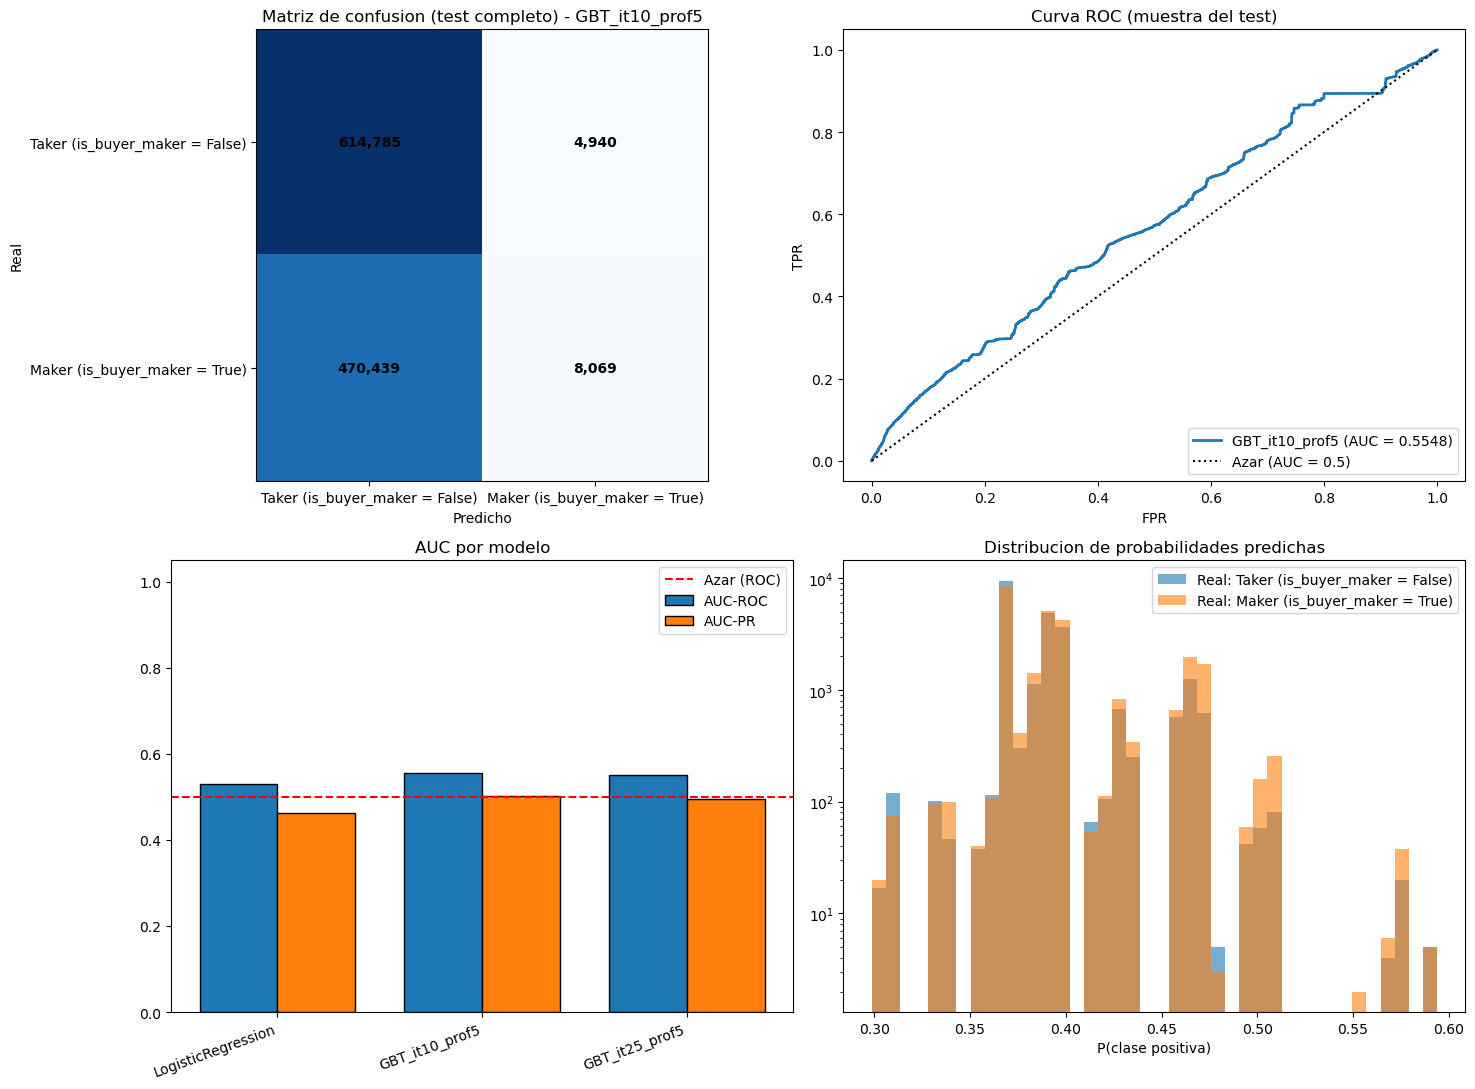

In [10]:
def curva_roc(y, s):
    o = np.argsort(-s); y = y[o]
    tps, fps = np.cumsum(y), np.cumsum(1 - y)
    return np.r_[0, fps / max(fps[-1], 1)], np.r_[0, tps / max(tps[-1], 1)]

n_graf = 50000
frac = min(1.0, n_graf * 1.2 / n_test)
pdf = (ganador.transform(df_test)
       .select("label", "prediction", vector_to_array("probability")[1].alias("prob"))
       .sample(False, frac, SEED).limit(n_graf).toPandas())
r = resultados[ganador_nombre]

fig, ax = plt.subplots(2, 2, figsize=(15, 11))

cm = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]])
im = ax[0, 0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[0, 0].text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontweight="bold")
ax[0, 0].set_xticks([0, 1]); ax[0, 0].set_yticks([0, 1])
ax[0, 0].set_xticklabels(["Taker (is_buyer_maker = False)", "Maker (is_buyer_maker = True)"]); ax[0, 0].set_yticklabels(["Taker (is_buyer_maker = False)", "Maker (is_buyer_maker = True)"])
ax[0, 0].set_xlabel("Predicho"); ax[0, 0].set_ylabel("Real")
ax[0, 0].set_title(f"Matriz de confusion (test completo) - {ganador_nombre}")

fpr, tpr = curva_roc(pdf["label"].to_numpy(), pdf["prob"].to_numpy())
ax[0, 1].plot(fpr, tpr, lw=2, label=f"{ganador_nombre} (AUC = {r['auc_roc']:.4f})")
ax[0, 1].plot([0, 1], [0, 1], "k:", label="Azar (AUC = 0.5)")
ax[0, 1].set_title("Curva ROC (muestra del test)"); ax[0, 1].set_xlabel("FPR"); ax[0, 1].set_ylabel("TPR"); ax[0, 1].legend(loc="lower right")

nombres = [n for n in resultados if not n.startswith("BASELINE")]
x = np.arange(len(nombres)); w = 0.38
ax[1, 0].bar(x - w/2, [resultados[n]["auc_roc"] for n in nombres], w, label="AUC-ROC", edgecolor="k")
ax[1, 0].bar(x + w/2, [resultados[n]["auc_pr"] for n in nombres], w, label="AUC-PR", edgecolor="k")
ax[1, 0].axhline(0.5, color="r", ls="--", label="Azar (ROC)")
ax[1, 0].set_xticks(x); ax[1, 0].set_xticklabels(nombres, rotation=20, ha="right")
ax[1, 0].set_ylim(0, 1.05); ax[1, 0].legend(); ax[1, 0].set_title("AUC por modelo")

for lab, nom, col in [(0.0, "Taker (is_buyer_maker = False)", "tab:blue"), (1.0, "Maker (is_buyer_maker = True)", "tab:orange")]:
    ax[1, 1].hist(pdf.loc[pdf["label"] == lab, "prob"], bins=40, alpha=0.6, label=f"Real: {nom}", color=col)
ax[1, 1].set_yscale("log"); ax[1, 1].set_title("Distribucion de probabilidades predichas")
ax[1, 1].set_xlabel("P(clase positiva)"); ax[1, 1].legend()

plt.tight_layout(); plt.show()

## 11. Resumen y lectura de resultados

In [11]:
g = resultados[ganador_nombre]
base = [v for k, v in resultados.items() if k.startswith("BASELINE")][0]
print("=" * 70)
print(f"INTEGRANTE {INTEGRANTE} - objetivo: is_buyer_maker_num")
print(f"Ganador: {ganador_nombre}")
print(f"{METRICA_SELECCION}: {g[METRICA_SELECCION]:.6f}  (baseline: {base.get(METRICA_SELECCION)})")
print(f"Modelo: {ruta_modelo}")
print(f"Gold ML: {ruta_gold}")
print(f"Gold KPI: {ruta_kpi}")
print("=" * 70)

INTEGRANTE 3 - objetivo: is_buyer_maker_num
Ganador: GBT_it10_prof5
auc_roc: 0.554819  (baseline: 0.5)
Modelo: /home/jovyan/work/artifacts/modelo_ganador_integrante3
Gold ML: /home/jovyan/work/artifacts/gold_integrante3
Gold KPI: /home/jovyan/work/artifacts/gold_kpi_integrante3


### Lectura esperada
- Con precio, cantidad y monto de **una sola operacion**, el rol maker/taker deberia quedar cerca del azar (AUC-ROC ≈ 0.5): depende de la intencion de los participantes (orden limite vs. orden a mercado), no de la forma del trade ejecutado. Un AUC modesto no es un fracaso: **es un hallazgo negativo valido** y se defiende como tal.
- Para que la dimension tenga una oportunidad real de señal, la Unidad 2 puede probar variables con **contexto temporal** (cambio de precio frente al trade anterior, ritmo de trades por segundo, desbalance reciente de agresores). Estas requieren estado o ventanas en streaming, a diferencia de las features de este notebook, que son sin estado.
- Se reporta tambien el baseline de clase mayoritaria para no confundir accuracy alta con capacidad predictiva.